In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from astropy.io import fits
from astropy.table import Table
import os

### Comparing the two stars with odd stellar paramaters (ra_1639-2632_s419 and ra_1659-2154_s261) to see if the issue is the reddening, or if its the parallax.

Loading in the data

In [2]:
# Loading in the stellar spectra of our stars
ra1639_spec = Table.read('/data/misfit/benlowe/xshooter/p115/reduced_data/comb_spec/ra_1639-2632_s419/ra_1639-2632_s419_data.fits', hdu=2)
ra1659_spec = Table.read('/data/misfit/benlowe/xshooter/p115/reduced_data/comb_spec/ra_1659-2154_s261/ra_1659-2154_s261_data.fits', hdu=2)

# Loading in the reference spectra
# ra_1648-0653_s38 (hot star with high logg)
# ra_1709-2130_s102 (cool star with low logg)
ra1648_refspec = Table.read('/data/misfit/benlowe/xshooter/p113/reduced_data/comb_spec_2/ra_1648-0653_s38/ra_1648-0653_s38_data.fits', hdu=2)
ra1709_refspec = Table.read('/data/misfit/benlowe/xshooter/p113/reduced_data/comb_spec_2/ra_1709-2130_s102/ra_1709-2130_s102_data.fits', hdu=2)
ra1633_refspec = Table.read('/data/misfit/benlowe/xshooter/p113/reduced_data/comb_spec_2/ra_1633-2814_s284/ra_1633-2814_s284_data.fits', hdu=2)

Plotting spectra for H-alpha

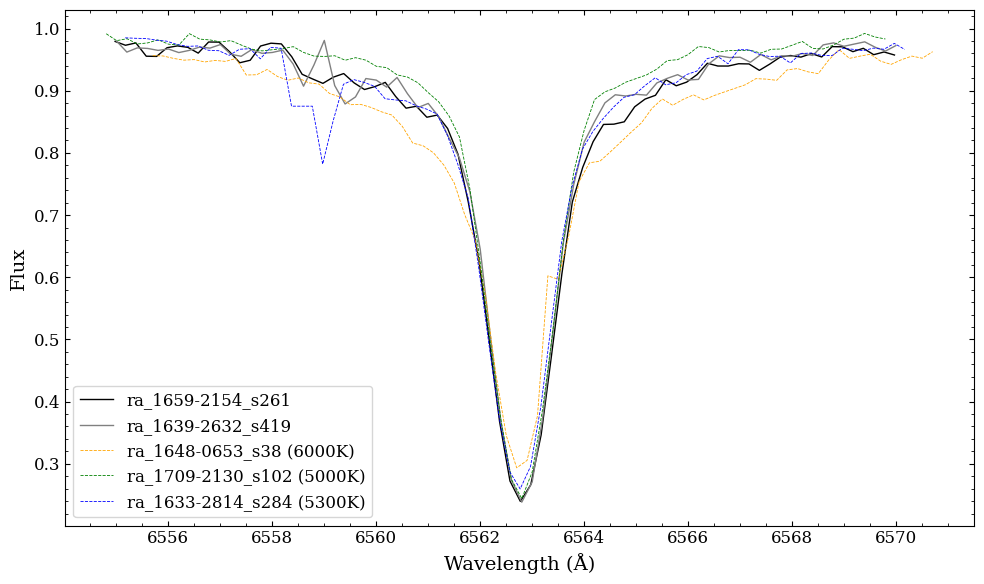

In [3]:
halpha_reg = np.where((ra1639_spec['wave'] > 6555) & (ra1639_spec['wave'] < 6570))

plt.figure(figsize=(10,6))
plt.plot(ra1659_spec['wave'][halpha_reg], ra1659_spec['flux'][halpha_reg], label='ra_1659-2154_s261', color='black', linewidth=1)
plt.plot(ra1639_spec['wave'][halpha_reg], ra1639_spec['flux'][halpha_reg], label='ra_1639-2632_s419', color='grey', linewidth=1)
plt.plot(ra1648_refspec['wave'][halpha_reg], ra1648_refspec['flux'][halpha_reg], 
         label='ra_1648-0653_s38 (6000K)', linestyle='--',
         color='orange', linewidth=0.6)
plt.plot(ra1709_refspec['wave'][halpha_reg], ra1709_refspec['flux'][halpha_reg], 
         label='ra_1709-2130_s102 (5000K)', linestyle='--',
         color='green', linewidth=0.6)
plt.plot(ra1633_refspec['wave'][halpha_reg], ra1633_refspec['flux'][halpha_reg], 
         label='ra_1633-2814_s284 (5300K)', linestyle='--',
         color='blue', linewidth=0.6)

plt.xlabel('Wavelength (Å)')
plt.ylabel('Flux')
plt.legend()
plt.tight_layout()
plt.savefig('/data/misfit/benlowe/xshooter/p115/results/tests/halpha_comparison.png', dpi=300)

### Running same test, but now for the Mg triplet

Loading in the data

In [46]:
# Loading in the stellar spectra of our stars
ra1639_uvb_spec = Table.read('/data/misfit/benlowe/xshooter/p115/reduced_data/comb_spec/ra_1639-2632_s419/ra_1639-2632_s419_data.fits', hdu=1)
ra1659_uvb_spec = Table.read('/data/misfit/benlowe/xshooter/p115/reduced_data/comb_spec/ra_1659-2154_s261/ra_1659-2154_s261_data.fits', hdu=1)

# Loading in the reference spectra
# ra_1648-0653_s38 (hot star with high logg)
# ra_1709-2130_s102 (cool star with low logg)
ra1648_uvb_refspec = Table.read('/data/misfit/benlowe/xshooter/p113/reduced_data/comb_spec_2/ra_1648-0653_s38/ra_1648-0653_s38_data.fits', hdu=1)
ra1709_uvb_refspec = Table.read('/data/misfit/benlowe/xshooter/p113/reduced_data/comb_spec_2/ra_1709-2130_s102/ra_1709-2130_s102_data.fits', hdu=1)
ra1633_uvb_refspec = Table.read('/data/misfit/benlowe/xshooter/p113/reduced_data/comb_spec_2/ra_1633-2814_s284/ra_1633-2814_s284_data.fits', hdu=1)

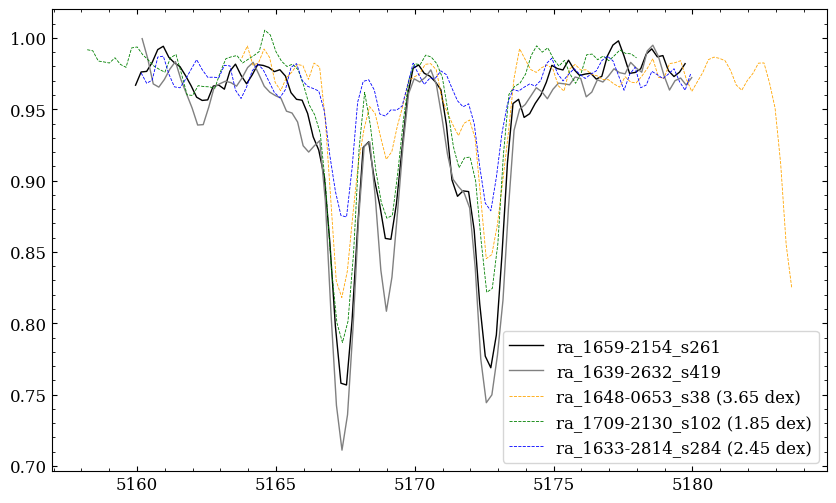

In [50]:
mg_reg = np.where((ra1639_uvb_spec['wave'] > 5160) & (ra1639_uvb_spec['wave'] < 5180))

plt.figure(figsize=(10,6))
plt.plot(ra1659_uvb_spec['wave'][mg_reg], ra1659_uvb_spec['flux'][mg_reg], label='ra_1659-2154_s261', color='black', linewidth=1)
plt.plot(ra1639_uvb_spec['wave'][mg_reg], ra1639_uvb_spec['flux'][mg_reg], label='ra_1639-2632_s419', color='grey', linewidth=1)
plt.plot(ra1648_uvb_refspec['wave'][mg_reg], ra1648_uvb_refspec['flux'][mg_reg], 
         label='ra_1648-0653_s38 (3.65 dex)', linestyle='--',
         color='orange', linewidth=0.6)
plt.plot(ra1709_uvb_refspec['wave'][mg_reg], ra1709_uvb_refspec['flux'][mg_reg], 
         label='ra_1709-2130_s102 (1.85 dex)', linestyle='--',
         color='green', linewidth=0.6)
plt.plot(ra1633_uvb_refspec['wave'][mg_reg], ra1633_uvb_refspec['flux'][mg_reg], 
         label='ra_1633-2814_s284 (2.45 dex)', linestyle='--',
         color='blue', linewidth=0.6)

plt.legend()

### Looking at how H-alpha changes with Teff and logg

Loading in the teff and logg synthetic spectra of H-alpha

In [26]:
# Loading in the teff change spectra
teff_path = '/data/misfit/benlowe/xshooter/p115/korg_data/test/stars_with_odd_stel_params/halpha_look/change_teff/'
teff_change_spec = [teff_path + f for f in os.listdir(teff_path) if f.endswith('.csv')]

# Loading in the logg change spectra
logg_path = '/data/misfit/benlowe/xshooter/p115/korg_data/test/stars_with_odd_stel_params/halpha_look/change_logg/'
logg_change_spec = [logg_path + f for f in os.listdir(logg_path) if f.endswith('.csv')]

Opening up each of the synthetic spectra

In [27]:
# Getting the synthetic spectra for teff changes
teff_spectra = {}
for spec in teff_change_spec:
    teff_val = spec.split('t')[-1].split('_')[0]

    df = pd.read_csv(spec)
    teff_wave = df['wave'].values
    teff_flux = df['flux'].values
    teff_spectra[teff_val] = (teff_wave, teff_flux)


# Getting the synthetic spectra for logg changes
logg_spectra = {}
for spec in logg_change_spec:
    logg_val = spec.split('logg')[-1].split('_')[0]
    logg_val = logg_val[0] + '.' + logg_val[1:]  # Adding decimal point

    df = pd.read_csv(spec)
    logg_wave = df['wave'].values
    logg_flux = df['flux'].values
    logg_spectra[logg_val] = (logg_wave, logg_flux)


In [43]:
1/4

0.25

Plotting the synthetic spectra

Text(0, 0.5, 'Flux')

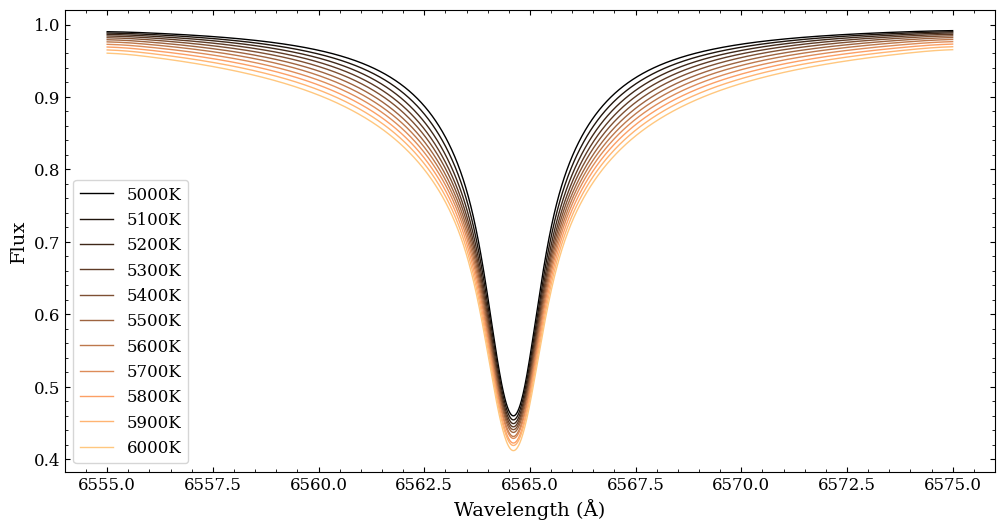

In [41]:
plt.figure(figsize=(12, 6))
colors = plt.cm.copper(np.linspace(0, 1, len(teff_spectra)))
for i, (teff_val, (wave, flux)) in enumerate(sorted(teff_spectra.items())):
    plt.plot(wave, flux, label=f'{teff_val}K', color=colors[i], linewidth=1)

plt.legend()
plt.xlabel('Wavelength (Å)')
plt.ylabel('Flux')

Text(0, 0.5, 'Flux')

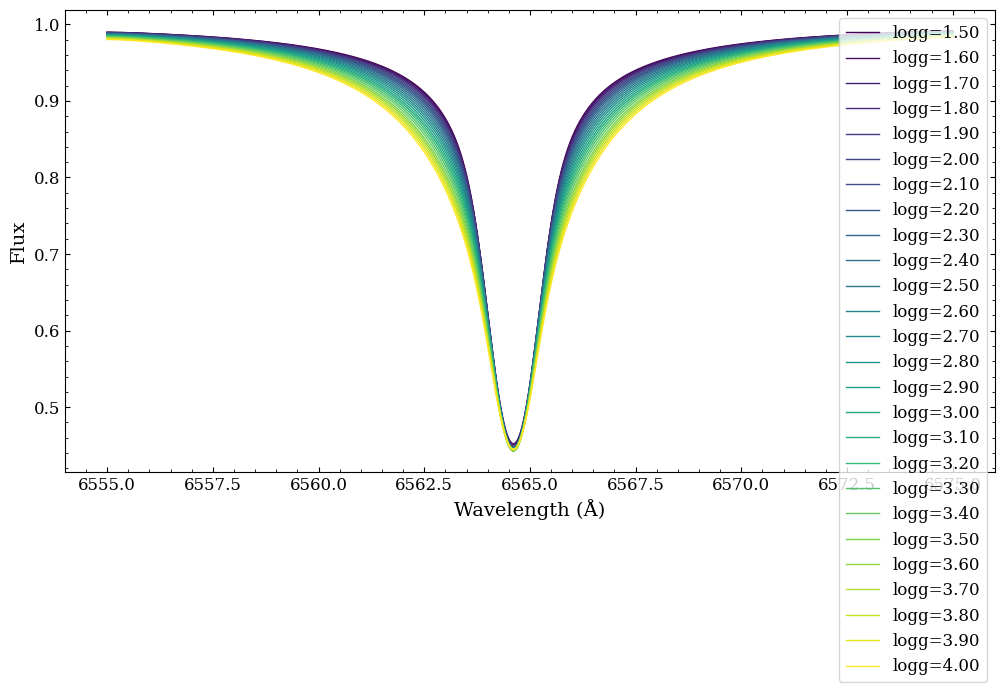

In [44]:
plt.figure(figsize=(12, 6))
colors = plt.cm.viridis(np.linspace(0, 1, len(logg_spectra)))
for i, (logg_val, (wave, flux)) in enumerate(sorted(logg_spectra.items())):
    plt.plot(wave, flux, label=f'logg={logg_val}', color=colors[i], linewidth=1)
    
plt.legend()
plt.xlabel('Wavelength (Å)')
plt.ylabel('Flux')